In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("15-lao-cai.csv", dtype={"sbd": str, "province_code": str})
df.head()

Matplotlib is building the font cache; this may take a moment.


,sbd,province_code,province_name,toan,ngu_van,ngoai_ngu,vat_li,hoa_hoc,sinh_hoc,lich_su,dia_li,gdcd,tin_hoc,cong_nghe,extra
0,15000001,15,Lào Cai,7.00,7.75,6.0,4.85,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,15000002,15,Lào Cai,3.00,6.50,NaN,NaN,NaN,NaN,6.25,NaN,NaN,NaN,NaN,Giáo dục kinh tế pháp luật=5.1
2,15000003,15,Lào Cai,6.00,6.75,NaN,4.75,NaN,NaN,9.75,NaN,NaN,NaN,NaN,NaN
3,15000004,15,Lào Cai,2.35,4.75,NaN,NaN,NaN,NaN,5.50,NaN,NaN,NaN,NaN,Giáo dục kinh tế pháp luật=5.1
4,15000005,15,Lào Cai,6.50,5.75,NaN,5.00,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
from pathlib import Path

DATA_DIR = Path(".")  # EDA.ipynb is in data/
READ_KW = {"dtype": {"sbd": str, "province_code": str}}
SKIP_FILES = {"diem_thi_thptqg_2026_all.csv"}  # skip if you already merged once

csv_files = sorted(
    f for f in DATA_DIR.glob("*.csv")
    if f.name not in SKIP_FILES
)

frames = [pd.read_csv(f, **READ_KW) for f in csv_files]
df = pd.concat(frames, ignore_index=True)

# one row per student (SBD is unique nationwide)
df = df.drop_duplicates(subset="sbd", keep="first")
df = df.sort_values("sbd").reset_index(drop=True)

print(f"Loaded {len(csv_files)} files → {len(df):,} rows")
df.head()

Loaded 34 files → 1,200,202 rows


,sbd,province_code,province_name,toan,ngu_van,ngoai_ngu,vat_li,hoa_hoc,sinh_hoc,lich_su,dia_li,gdcd,tin_hoc,cong_nghe,extra
0,01000001,01,Hà Nội,4.50,7.50,NaN,NaN,NaN,NaN,8.50,7.75,NaN,NaN,NaN,NaN
1,01000002,01,Hà Nội,6.50,7.50,NaN,NaN,NaN,NaN,8.75,4.85,NaN,NaN,NaN,NaN
2,01000003,01,Hà Nội,6.50,7.50,NaN,6.85,6.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,01000004,01,Hà Nội,5.50,7.25,NaN,4.10,4.30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,01000005,01,Hà Nội,7.25,7.50,NaN,7.75,7.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
df.shape

(1200202, 15)

In [16]:
df['ngoai_ngu'].isna().sum()

np.int64(1070976)

In [23]:
df_eng = df[['sbd','province_name','ngoai_ngu']].drop_duplicates()
df_toan = df[['sbd','province_name','toan']].drop_duplicates()
df_eng,df_toan

(              sbd province_name  ngoai_ngu
 0        01000001        Hà Nội        NaN
 1        01000002        Hà Nội        NaN
 2        01000003        Hà Nội        NaN
 3        01000004        Hà Nội        NaN
 4        01000005        Hà Nội        NaN
 ...           ...           ...        ...
 1200197  96019662        Cà Mau        NaN
 1200198  96019663        Cà Mau        NaN
 1200199  96019664        Cà Mau        NaN
 1200200  96019665        Cà Mau        NaN
 1200201  96019667        Cà Mau        NaN
 
 [1200202 rows x 3 columns],
               sbd province_name  toan
 0        01000001        Hà Nội  4.50
 1        01000002        Hà Nội  6.50
 2        01000003        Hà Nội  6.50
 3        01000004        Hà Nội  5.50
 4        01000005        Hà Nội  7.25
 ...           ...           ...   ...
 1200197  96019662        Cà Mau   NaN
 1200198  96019663        Cà Mau   NaN
 1200199  96019664        Cà Mau   NaN
 1200200  96019665        Cà Mau   NaN
 1200201  96

/var/folders/7n/ft5mp9fx4zj20xbbb01l4hh40000gp/T/ipykernel_69818/3497232714.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, fontsize=8)


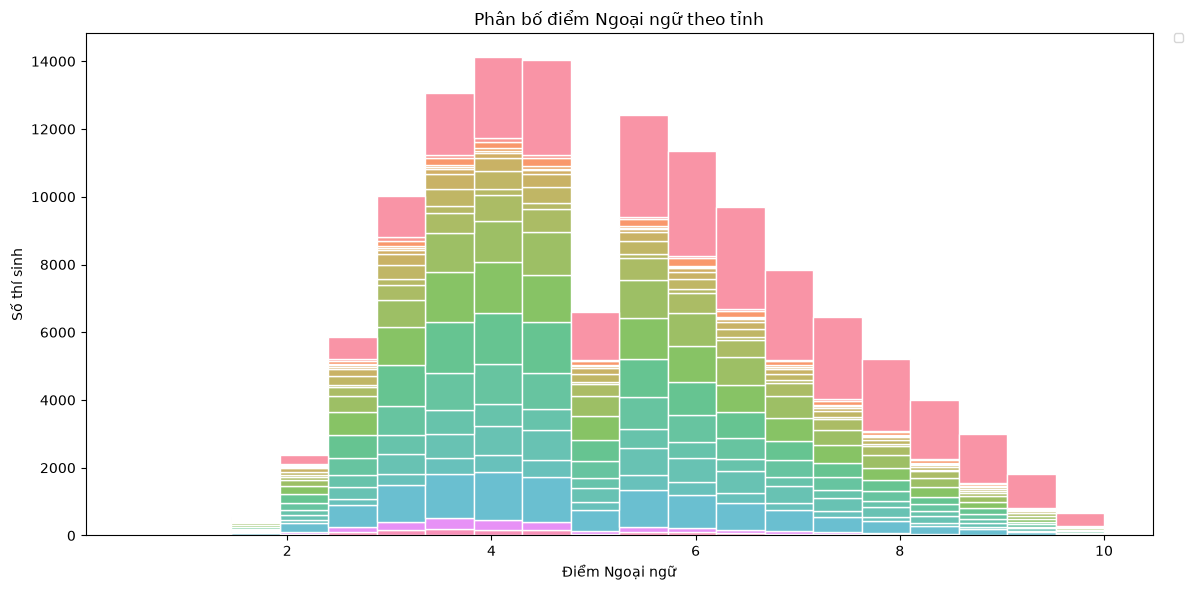

In [15]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_eng,
    x="ngoai_ngu",
    hue="province_name",
    multiple="stack",
    bins=20,
    edgecolor="white",
)

plt.title("Phân bố điểm Ngoại ngữ theo tỉnh")
plt.xlabel("Điểm Ngoại ngữ")
plt.ylabel("Số thí sinh")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, fontsize=8)
plt.tight_layout()
plt.show()

/var/folders/7n/ft5mp9fx4zj20xbbb01l4hh40000gp/T/ipykernel_69818/3136528871.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, fontsize=8)


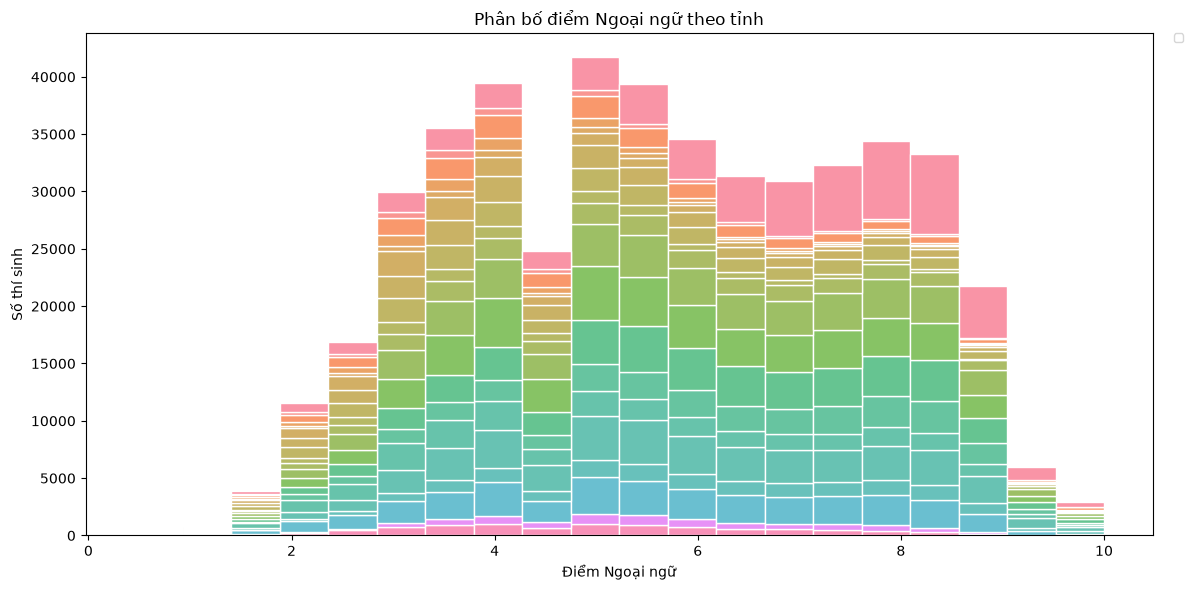

In [25]:
plt.figure(figsize=(12, 6))

sns.histplot(
    data=df_toan,
    x="toan",
    hue="province_name",
    multiple="stack",
    bins=20,
    edgecolor="white",
)

plt.title("Phân bố điểm Ngoại ngữ theo tỉnh")
plt.xlabel("Điểm Ngoại ngữ")
plt.ylabel("Số thí sinh")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, fontsize=8)
plt.tight_layout()
plt.show()

/var/folders/7n/ft5mp9fx4zj20xbbb01l4hh40000gp/T/ipykernel_69818/523187663.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, fontsize=8)


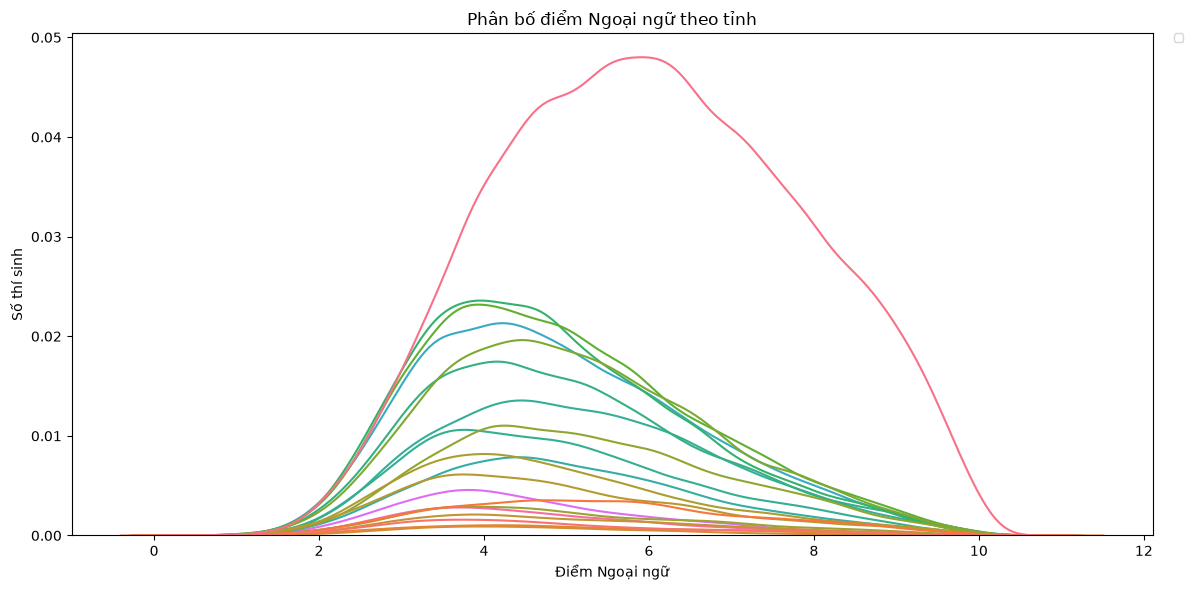

In [21]:
plt.figure(figsize=(12, 6))

sns.kdeplot(
    data=df_eng,
    x="ngoai_ngu",
    hue="province_name",
    legend=True
)

plt.title("Phân bố điểm Ngoại ngữ theo tỉnh")
plt.xlabel("Điểm Ngoại ngữ")
plt.ylabel("Số thí sinh")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0, fontsize=8)
plt.tight_layout()
plt.show()

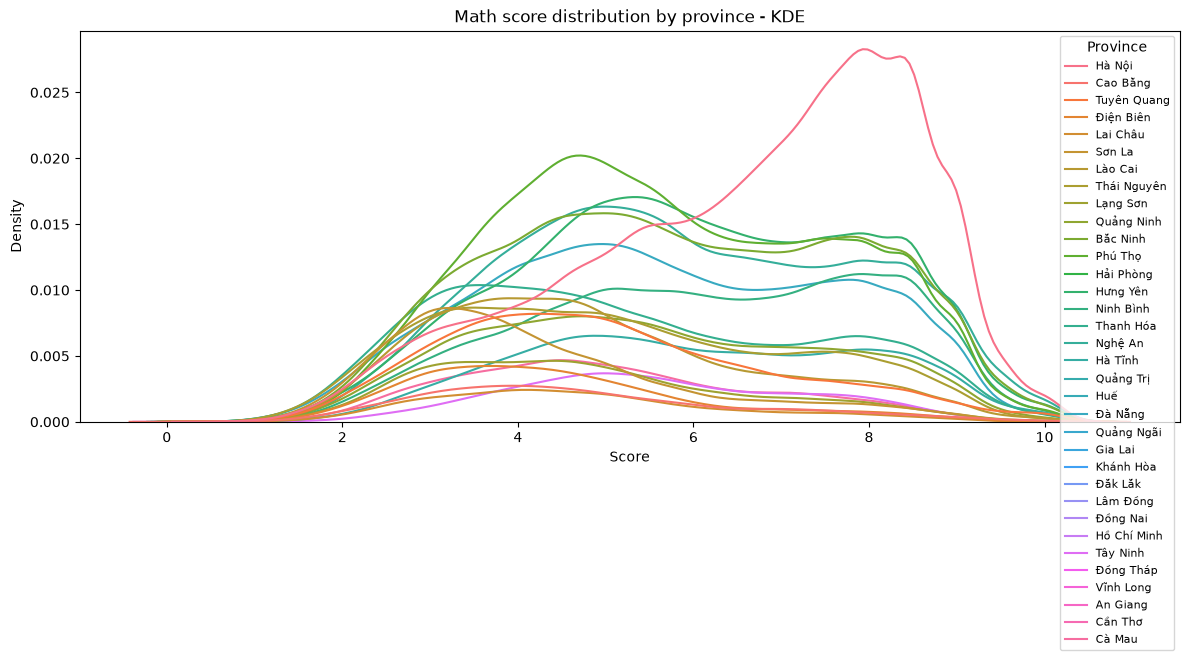

In [36]:
plt.figure(figsize=(12, 6))

ax = sns.kdeplot(
    data=df_toan,
    x="toan",
    hue="province_name",
)

plt.title("Math score distribution by province - KDE")
plt.xlabel("Score")
plt.ylabel("Density")
sns.move_legend(ax, "upper right", title="Province", fontsize=8)
plt.tight_layout()
plt.show()

In [50]:
df_toan[df_toan["province_name"] == 'Hà Nội']['toan'].describe()

count    53706.000000
mean         6.611711
std          1.888034
min          0.700000
25%          5.250000
50%          7.000000
75%          8.000000
max         10.000000
Name: toan, dtype: float64

In [48]:
df_toan[df_toan["province_name"] == 'Hà Nội']['sbd'].nunique()

125419

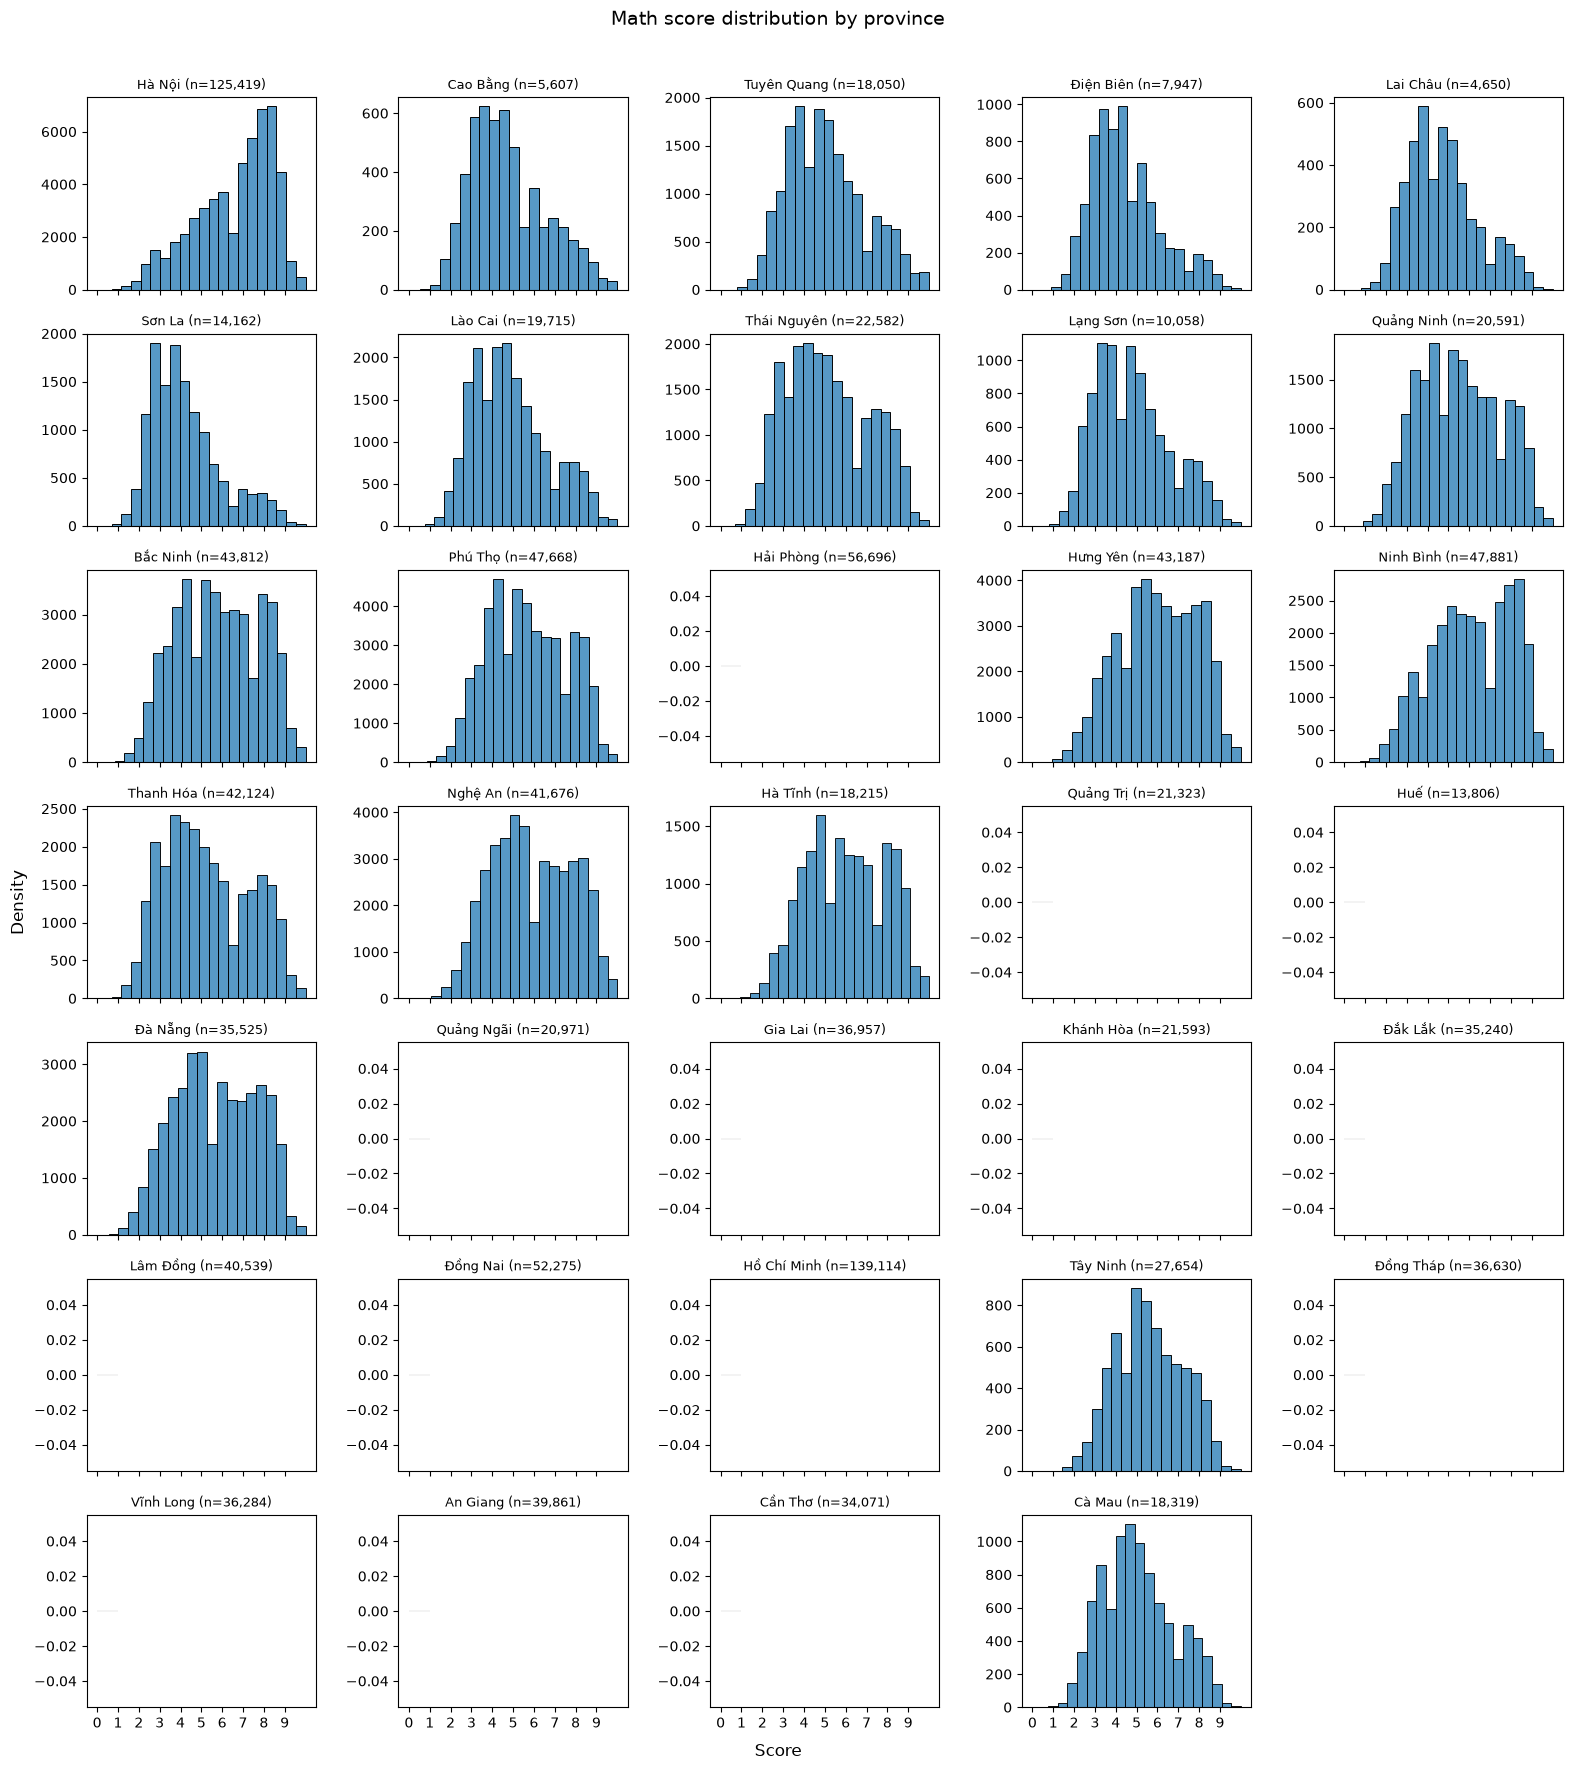

In [51]:
ncols = 5
nrows = (len(df['province_name'].unique()) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.2, nrows * 2.5), sharex=True, sharey=False)
axes = axes.flatten()

for i, province in enumerate(df['province_name'].unique()):
    ax = axes[i]
    subset = df_toan[df_toan["province_name"] == province]

    if not subset.empty:
        sns.histplot(data=subset, x="toan", ax=ax, bins = 20)
    else:
        ax.text(0.5, 0.5, "Không có dữ liệu", ha="center", va="center", transform=ax.transAxes, fontsize=9)

    n_students = subset["sbd"].nunique() if not subset.empty else 0
    ax.set_title(f"{province} (n={n_students:,})", fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")

    n_students = subset["sbd"].nunique() if not subset.empty else 0
    ax.set_title(f"{province} (n={n_students:,})", fontsize=9)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.supxlabel("Score")
fig.supylabel("Density")
fig.suptitle(f"Math score distribution by province", fontsize=14, y=1.01)
plt.tight_layout()
plt.xticks(np.arange(0, 10, 1))
plt.show()

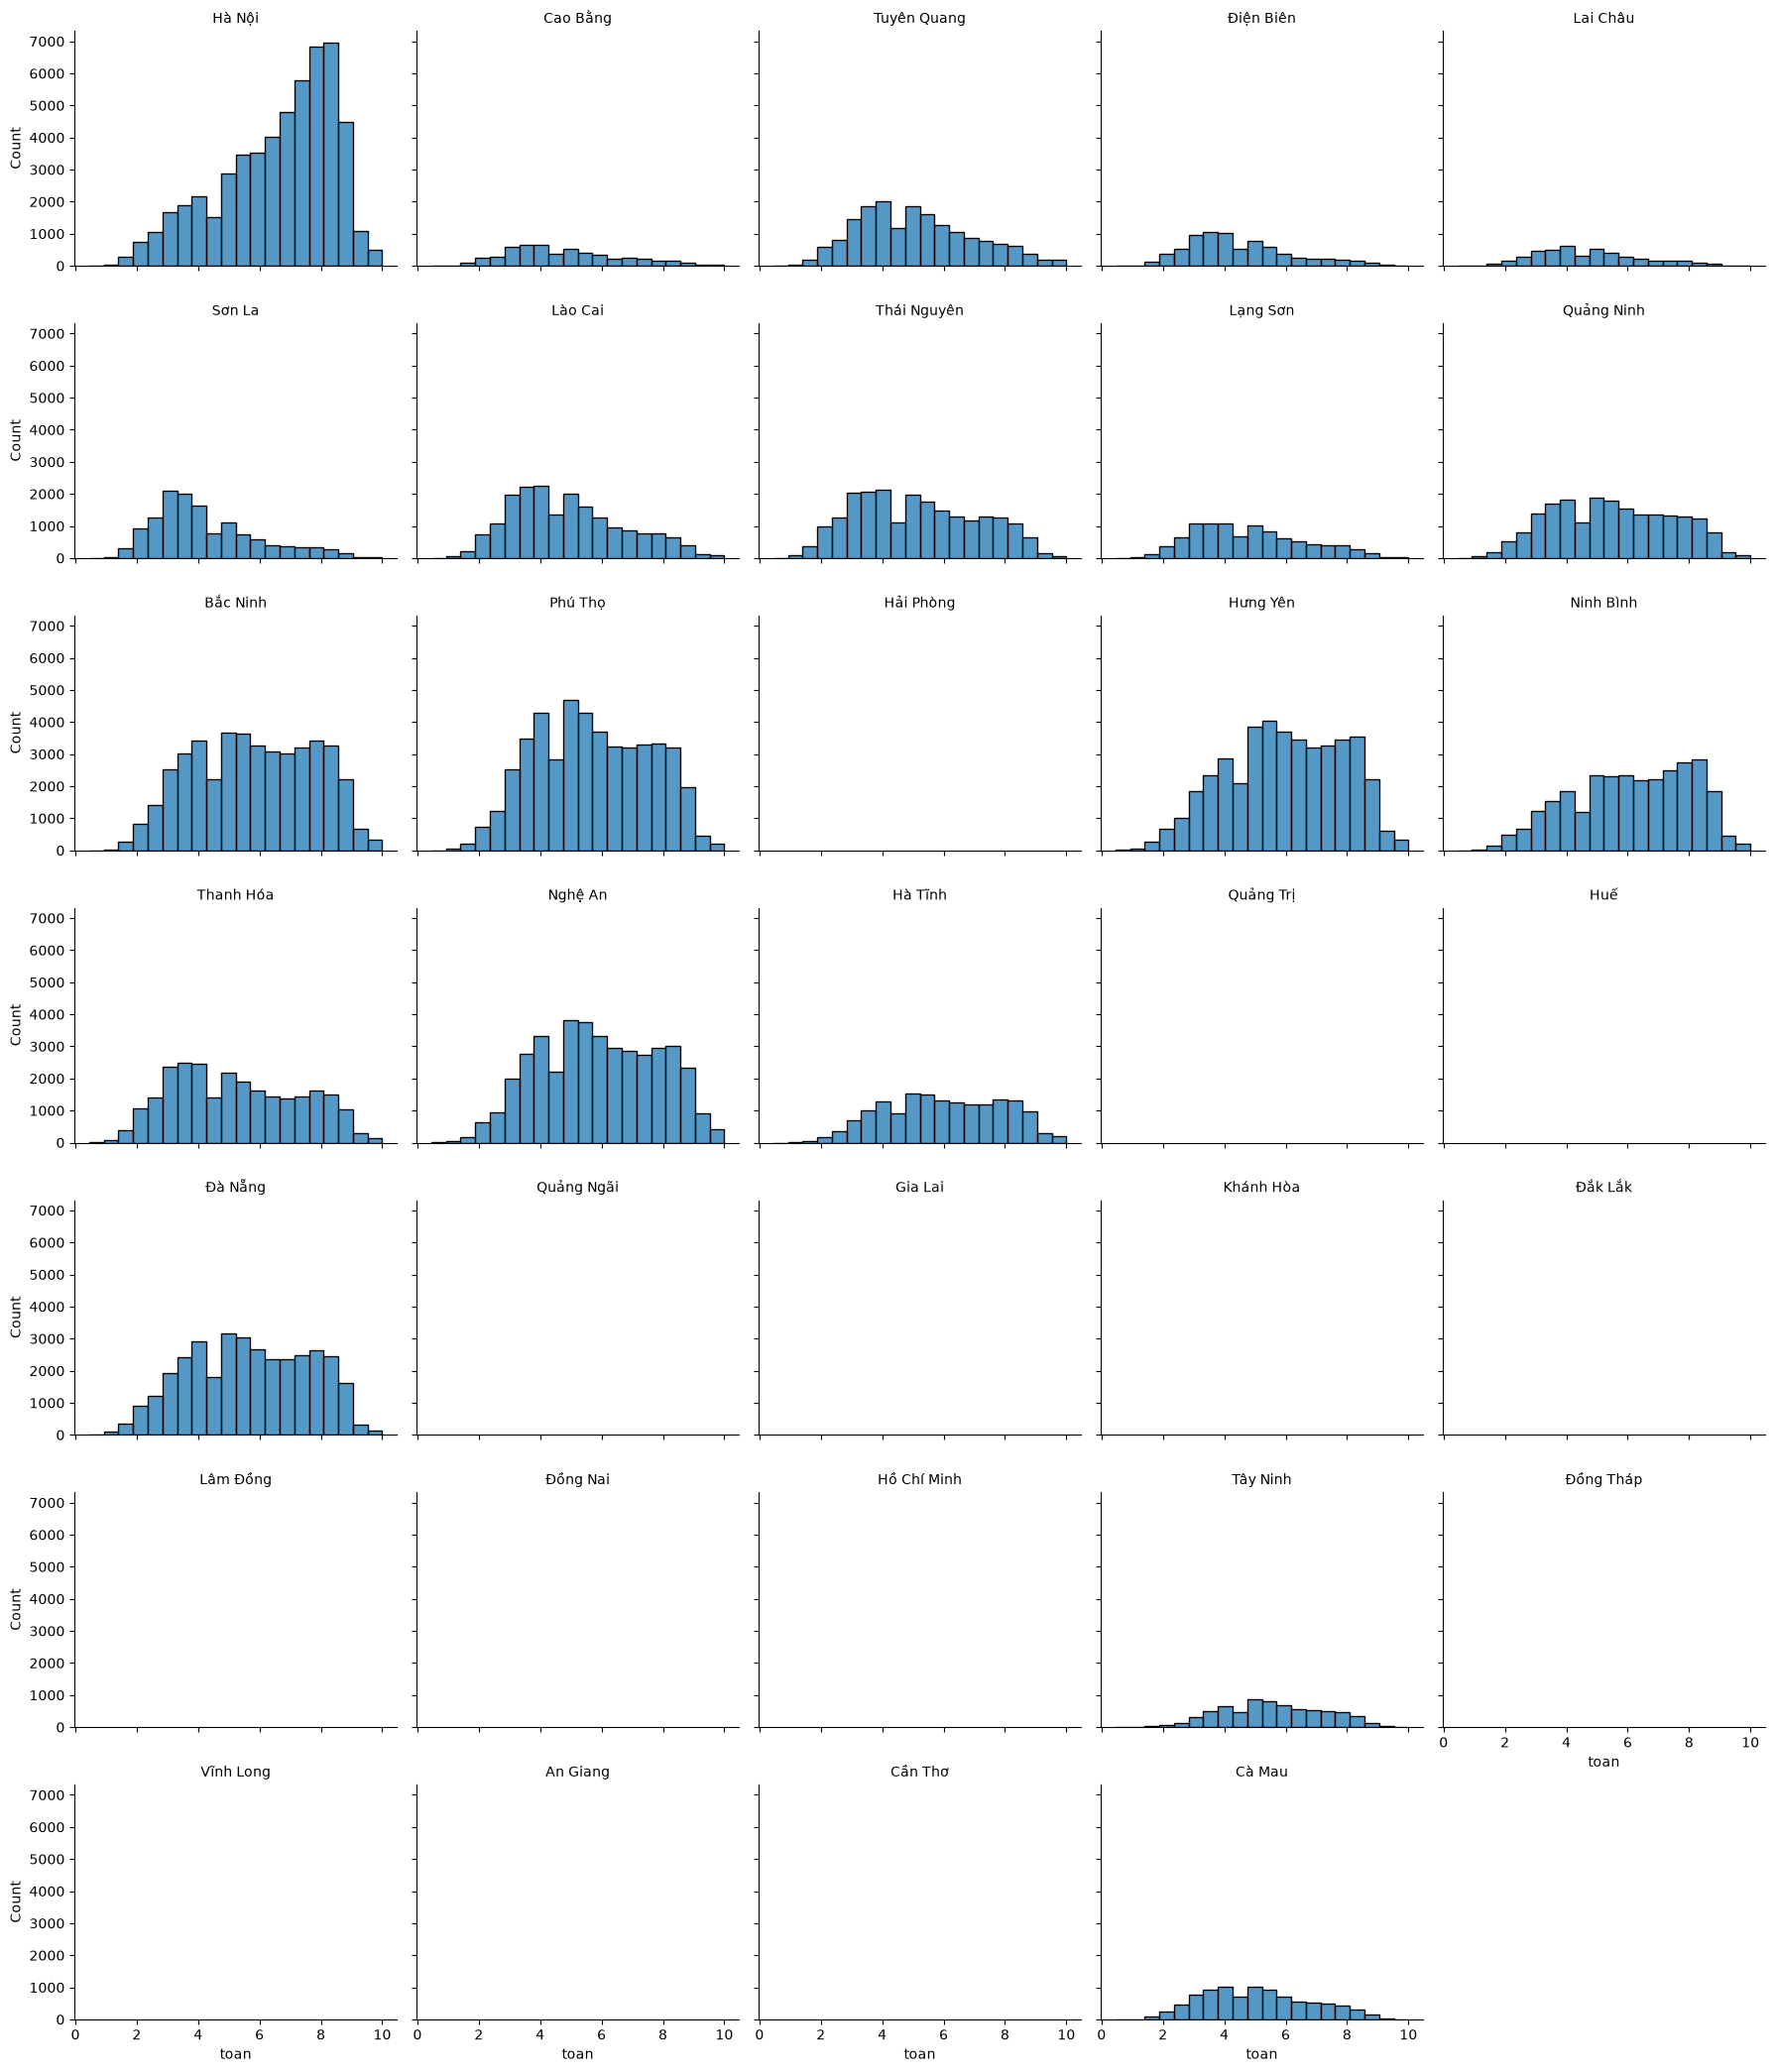

In [43]:
g = sns.displot(
    data=df_toan,
    x="toan",
    col="province_name",
    col_wrap=5,
    bins=20,
    height=3,
    aspect=1.2,
)
g.set_titles("{col_name}")
plt.show()